# Class 05 · Part 1: Getting simulation data on HEALPix

So far you used **observations**: stations, E-OBS, satellites. Now you use the output of a **climate
model**: a simulation of the Earth's climate made by a computer. To know how good a model is, we compare
it with observations; the difference is its **bias**. In this notebook you learn

1. what the **nextGEMS** simulations and their **catalog** are,
2. what the **HEALPix** grid is, the grid of these simulations,
3. how to open a simulation and draw a first map, and
4. how to compute **monthly means** and save them, for part 2.

In part 2, `class05_evaluate_models.ipynb`, you compare the model with ERA5 and see its biases.

## 1. nextGEMS and its catalog

**nextGEMS** is a European project that ran global simulations at kilometre scale with the models ICON and
IFS. Their output, and data to compare it with, are listed in a **catalog**: a list of datasets with
their address and how to open them. The package `intake` reads it:

In [ ]:
import intake

cat = intake.open_catalog("https://data.nextgems-h2020.eu/online.yaml")
list(cat)

`ICON` and `IFS` are the models; `ERA5`, `JRA3Q` and `MERRA2` are reanalyses (class 07); `IMERG` and
`GSMaP` satellite precipitation (class 04). Each model has several simulations:

In [ ]:
list(cat.ICON)

A dataset of the catalog has **parameters**: the time step of the output and the zoom level of the grid:

In [ ]:
import pandas as pd

pd.DataFrame(cat.ICON.ngc4008.describe()["user_parameters"])

We use the simulation **`ngc4008`**: daily output from 2020 to 2050. (The IFS simulation of the catalog
is not accessible at the moment, so this class uses ICON.)

## 2. The HEALPix grid

In class 03 the grid was a chess board of longitudes and latitudes, and its cells got smaller towards the
poles, so a mean needed weights. **HEALPix** cuts the sphere differently: into **12 cells of equal area**,
and then every cell again into 4, and again, and again:

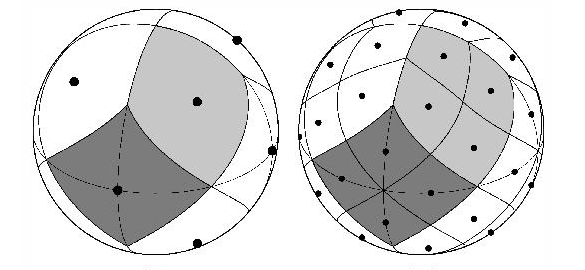

- The number of splits is the **zoom level** $z$.
- A grid of zoom $z$ has $N_\mathrm{cells} = 12 \cdot 4^z$ cells, and $\mathrm{nside} = 2^z$.
- **All cells have the same area.** So the global mean is a plain mean over the cells: no weights.

| zoom | cells | spacing |
|---:|---:|---:|
| 6 | 49 152 | ~100 km |
| 7 | 196 608 | ~50 km |
| 10 | 12 582 912 | ~6 km |

In this class we use **zoom 6**: enough for maps of the globe, and 4 times less data than zoom 7.
Class 06 is about the zoom levels.

A HEALPix dataset has no latitude and longitude for its cells, only a cell **number**. The package `healpix`
converts between cell numbers and positions, as you will see in part 2.

## 3. Open a simulation

`cat.ICON.ngc4008(zoom=6, time="P1D")` chooses the parameters (`P1D`: one value per day), and `.to_dask()`
opens it **lazily**, as in class 03: nothing is downloaded until you need the values.

In [ ]:
icon = cat.ICON.ngc4008(zoom=6, time="P1D").to_dask()
icon

About 100 variables, with only two dimensions: `time` and `cell`. We use the **2 m temperature**, `tas`:

In [ ]:
icon["tas"].attrs

A first map: one day, in °C. A HEALPix map is drawn with `healpix_show` from the package `easygems`,
on a map of `cartopy` as in class 03.

In [ ]:
import cartopy.crs as ccrs
import easygems.healpix as egh
import matplotlib.pyplot as plt

one_day = icon["tas"].sel(time="2021-07-15") - 273.15  # K to °C

fig = plt.figure(figsize=(10, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()
ax.coastlines(linewidth=0.5)
image = egh.healpix_show(one_day.squeeze(), ax=ax, cmap="RdYlBu_r", vmin=-40, vmax=40)
fig.colorbar(image, ax=ax, shrink=0.7, label="temperature / °C")
ax.set_title("ICON ngc4008, 2 m temperature, 15 July 2021")
plt.show()

## 4. Monthly means, saved

To compare with ERA5, which has one value per month, we compute the **monthly means of 2021–2023**. That
reads three years of daily data, about 200 MB: it can take **a few minutes**. So we do it once and **save**
the result in `data`, like a download. `.to_netcdf` writes a netCDF file; the next time, the `if` skips the
work.

In [ ]:
import pathlib

pathlib.Path("data").mkdir(exist_ok=True)
icon_file = pathlib.Path("data/icon_ngc4008_tas_monthly_2021-2023_zoom6.nc")

if not icon_file.exists():
    tas = icon["tas"].sel(time=slice("2021-01-01", "2023-12-31"))
    tas.resample(time="MS").mean().to_netcdf(icon_file)

print(icon_file, round(icon_file.stat().st_size / 1e6, 1), "MB")

And the same for **ERA5**, the reference, also at zoom 6. Its 2 m temperature is called `2t`. ERA5 has
monthly means already, so this is fast:

In [ ]:
era5_file = pathlib.Path("data/era5_2t_monthly_2021-2023_zoom6.nc")

if not era5_file.exists():
    era5 = cat.ERA5(zoom=6).to_dask()
    era5["2t"].sel(time=slice("2021", "2023")).to_netcdf(era5_file)

print(era5_file, round(era5_file.stat().st_size / 1e6, 1), "MB")

## 5. Exercise

The catalog has a second ICON simulation with 2021–2023: **`ngc3028`**.

1. Look at its parameters with `describe()`. Which zoom levels and time steps does it have?
2. Compute its monthly means of the 2 m temperature for 2021–2023 at zoom 6, and save them as
   `data/icon_ngc3028_tas_monthly_2021-2023_zoom6.nc`, as in section 4.

In [ ]:
# 1. the parameters of ngc3028

In [ ]:
# 2. its monthly means, saved

## Next

Open **`class05_evaluate_models.ipynb`**: maps, the bias of the model, and time series.